## Platform diagnostics for A/B test

В основном notebook анализируется overall-эффект A/B-теста.  
В этом notebook дополнительно проверяется, одинаково ли эффект проявляется на `Mobile` и `Desktop`.

Цель — выявить возможную неоднородность эффекта по платформам.

### Загрузка данных эксперимента, подготовка и проведение EDA (предварительный анализ данных).

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('csv/marketpele_ab_test_data_set.csv', sep=',')

In [3]:
df.columns = df.columns.str.strip()
df['revenue'] = df['revenue'].str.replace('$', '', regex=False).str.replace(',', '.', regex=False)
df['revenue'] = df['revenue'].str.replace(r'\s+', '', regex=True).astype('Float64')

In [4]:
int_columns = ['pageviews', 'visible_pageviews', 'sessions']

for column in int_columns:
    df[column] = (
        df[column]
        .str.replace(r'\s+', '', regex=True)
        .astype('Int64')
    )

## Platform-level diagnostics

В основном анализе эффект оценивался по всем платформам вместе.  
Однако агрегированный overall-эффект может скрывать разную динамику на Desktop и Mobile.

Например:

- эффект может быть сильным на Mobile, но слабым на Desktop;
- эффект может быть положительным на одной платформе и отрицательным на другой;
- overall-результат может выглядеть умеренным, если эффекты по платформам различаются.

Поэтому дополнительно проверим те же ratio-метрики отдельно для `Desktop` и `Mobile`.

Метод остаётся тем же: paired bootstrap по matched-блокам  
`date + publisher_id + platform`.

Bootstrap многократно пересчитывает ratio-метрику и даёт распределение эффекта для оценки доверительного интервала.

In [5]:
import numpy as np

def bootstrap_ratio_paired(
    a_numerator,
    a_denominator,
    b_numerator,
    b_denominator,
    n_bootstrap=10_000,
    multiplier=1
):
    """
    Paired Poisson bootstrap для ratio-метрики.

    Элементы A и B с одинаковым индексом должны относиться
    к одному matched-блоку: date + publisher_id + platform.
    """

    weights = np.random.poisson(
        1,
        size=(n_bootstrap, len(a_numerator))
    )

    global_a = (
        np.sum(weights * a_numerator, axis=1)
        / np.sum(weights * a_denominator, axis=1)
        * multiplier
    )

    global_b = (
        np.sum(weights * b_numerator, axis=1)
        / np.sum(weights * b_denominator, axis=1)
        * multiplier
    )

    return global_a, global_b

### Hypothesis logic

Для monetization-метрик проверяем рост в группе B:

- RPM
- RPS
- Paid CTR

Для guardrail-метрик проверяем снижение в группе B:

- Organic CTR
- Pages per Session

Для каждой метрики расчёт выполняется отдельно для `Overall`, `Mobile` и `Desktop`.


### Универсальная функция для расчёта ratio-метрик по платформам

Дальше используется одна функция для всех ratio-метрик.  
Метрика задаётся через числитель, знаменатель и множитель.

Функция может считать как общий эффект по всем платформам (`platform=None`), так и эффект отдельно для `Desktop` или `Mobile`.

Bootstrap-единица остаётся одинаковой: `date + publisher_id + platform`.  
Это сохраняет matched-структуру A/B-пар и позволяет сравнивать группы внутри одинаковых блоков.

Используемые метрики:

- `RPM = revenue / pageviews × 1000`
- `RPS = revenue / sessions × 1000`
- `Paid CTR = sponsord_clicks / visible_pageviews × 100`
- `Organic CTR = organic_clicks / visible_pageviews × 100`
- `Pages per Session = pageviews / sessions`

In [6]:
def analyze_ratio_metric_by_platform(df, platform, numerator_col, denominator_col, metric_name, multiplier=1, n_bootstrap=10_000, alpha=0.05):
    """
    Расчёт ratio-метрики через paired bootstrap.
    Если platform=None, считается overall.
    Если platform задана, расчёт выполняется только для выбранной платформы.
    Bootstrap-единица: date + publisher_id + platform.
    """
    if platform is None:
        df_platform = df.copy()
        platform_label = 'Overall'
    else:
        df_platform = df[df['platform'] == platform].copy()
        platform_label = platform
    block_cols = ['date', 'publisher_id', 'platform']
    # Собираем данные по блокам и группам
    block_data = (df_platform.groupby(block_cols + ['group_name'], as_index=False).agg(numerator=(numerator_col, 'sum'), denominator=(denominator_col, 'sum')))
    # Одна строка = один блок date + publisher_id + platform.
    # Внутри строки отдельно лежат значения A и B.
    wide = block_data.pivot_table(index=block_cols, columns='group_name', values=['numerator', 'denominator'], aggfunc='sum')
    a_numerator = wide[('numerator', 'A')].to_numpy()
    a_denominator = wide[('denominator', 'A')].to_numpy()
    b_numerator = wide[('numerator', 'B')].to_numpy()
    b_denominator = wide[('denominator', 'B')].to_numpy()
    metric_a = (a_numerator.sum() / a_denominator.sum()* multiplier)
    metric_b = (b_numerator.sum() / b_denominator.sum() * multiplier)
    absolute_difference = metric_b - metric_a
    relative_difference_pct = (metric_b / metric_a - 1) * 100
    bootstrap_metric_a, bootstrap_metric_b = bootstrap_ratio_paired(
        a_numerator=a_numerator,
        a_denominator=a_denominator,
        b_numerator=b_numerator,
        b_denominator=b_denominator,
        n_bootstrap=n_bootstrap,
        multiplier=multiplier)
    bootstrap_difference = bootstrap_metric_b - bootstrap_metric_a
    bootstrap_relative_difference_pct = (bootstrap_metric_b / bootstrap_metric_a - 1) * 100
    lower_bound = np.quantile(bootstrap_difference, alpha)
    upper_bound = np.quantile(bootstrap_difference, 1 - alpha)
    relative_difference_lower_pct = np.quantile(bootstrap_relative_difference_pct, alpha)
    relative_difference_upper_pct = np.quantile(bootstrap_relative_difference_pct,1 - alpha)
    return {
        'metric': metric_name,
        'platform': platform_label,

        'metric_a': metric_a,
        'metric_b': metric_b,

        'absolute_difference': absolute_difference,
        'relative_difference_pct': relative_difference_pct,

        # absolute bootstrap CI
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'ci_width': upper_bound - lower_bound,
        'bootstrap_diff_std': np.std(bootstrap_difference),

        # relative bootstrap CI
        'relative_difference_lower_pct': relative_difference_lower_pct,
        'relative_difference_upper_pct': relative_difference_upper_pct,
        'relative_difference_ci_width_pct': (
            relative_difference_upper_pct - relative_difference_lower_pct
        ),
        'bootstrap_relative_difference_std_pct': np.std(bootstrap_relative_difference_pct),
        'n_blocks': len(wide)}

### RPM by platform

Сначала проверим RPM отдельно для `Overall`, `Mobile` и `Desktop`.

`RPM = revenue / pageviews × 1000`

Для каждой платформы используем тот же paired bootstrap-подход.  
Проверяем направленную гипотезу:

- `H0`: RPM в группе B не выше, чем в группе A
- `H1`: RPM в группе B выше, чем в группе A

Рост считаем статистически подтверждённым, если нижняя граница одностороннего 95% bootstrap confidence interval выше нуля.

In [7]:
np.random.seed(42)

rpm_platform_results = []

for platform in [None, 'Mobile', 'Desktop']:
    result = analyze_ratio_metric_by_platform(
        df=df,
        platform=platform,
        numerator_col='revenue',
        denominator_col='pageviews',
        metric_name='RPM',
        multiplier=1000,
        n_bootstrap=10_000,
        alpha=0.05
    )

    rpm_platform_results.append(result)

rpm_platform_results = pd.DataFrame(rpm_platform_results)
rpm_platform_results['is_significant_increase'] = (rpm_platform_results['lower_bound'] > 0)
rpm_platform_results['conclusion'] = np.where(rpm_platform_results['is_significant_increase'], 'Significant increase', 'Not significant')
rpm_platform_results

,metric,platform,metric_a,metric_b,absolute_difference,relative_difference_pct,lower_bound,upper_bound,ci_width,bootstrap_diff_std,relative_difference_lower_pct,relative_difference_upper_pct,relative_difference_ci_width_pct,bootstrap_relative_difference_std_pct,n_blocks,is_significant_increase,conclusion
0,RPM,Overall,1.563731,1.806238,0.242506,15.508192,0.122614,0.381618,0.259004,0.079542,8.077988,24.185909,16.107921,4.943357,63,True,Significant increase
1,RPM,Mobile,1.485335,1.831176,0.345842,23.283754,0.176740,0.585824,0.409084,0.124707,12.802223,36.763544,23.961322,7.467618,28,True,Significant increase
2,RPM,Desktop,1.688332,1.766317,0.077985,4.619071,-0.063770,0.238547,0.302318,0.092741,-3.493036,15.016440,18.509475,5.722839,35,False,Not significant


Здесб и далее `n_blocks` показывает количество matched-блоков, использованных в paired bootstrap.  
Эта величина не используется как вес при расчёте метрики, но помогает интерпретировать ширину bootstrap-интервалов: после разбиения на платформы число блоков уменьшается, поэтому оценки по сегментам могут быть менее стабильными.

Overall ratio-метрики считаются через суммы числителя и знаменателя по всем блокам. Поэтому вклад платформ в overall определяется объёмом соответствующего denominator: `pageviews` для RPM, `sessions` для RPS и `visible_pageviews` для CTR.

Mobile показывает самый сильный uplift RPM: +23.28%, и рост статистически подтверждён, так как нижняя граница одностороннего bootstrap confidence interval выше нуля.
На Desktop точечный uplift RPM составляет +4.62%, но нижняя bootstrap-граница ниже нуля, поэтому статистически значимый рост не подтверждается.
После разделения по платформам видно, что overall-эффект неоднороден: основной вклад в рост RPM даёт Mobile, тогда как Desktop не показывает надёжного эффекта.
Интервалы по отдельным платформам шире, чем overall, потому что после разбиения уменьшается число matched-блоков: 28 для Mobile и 35 для Desktop против 63 overall.

### RPS by platform

`RPS = revenue / sessions × 1000`

Как и для RPM, проверяем направленную гипотезу о росте метрики в группе B:

- `H0`: RPS в группе B не выше, чем в группе A
- `H1`: RPS в группе B выше, чем в группе A

Рост считаем статистически подтверждённым, если нижняя граница одностороннего 95% bootstrap confidence interval выше нуля.

In [8]:
np.random.seed(42)

rps_platform_results = []

for platform in [None, 'Mobile', 'Desktop']:
    result = analyze_ratio_metric_by_platform(
        df=df,
        platform=platform,
        numerator_col='revenue',
        denominator_col='sessions',
        metric_name='RPS',
        multiplier=1000,
        n_bootstrap=10_000,
        alpha=0.05
    )

    rps_platform_results.append(result)

rps_platform_results = pd.DataFrame(rps_platform_results)
rps_platform_results['is_significant_increase'] = (rps_platform_results['lower_bound'] > 0)
rps_platform_results['conclusion'] = np.where(rps_platform_results['is_significant_increase'],'Significant increase', 'Not significant')
rps_platform_results

,metric,platform,metric_a,metric_b,absolute_difference,relative_difference_pct,lower_bound,upper_bound,ci_width,bootstrap_diff_std,relative_difference_lower_pct,relative_difference_upper_pct,relative_difference_ci_width_pct,bootstrap_relative_difference_std_pct,n_blocks,is_significant_increase,conclusion
0,RPS,Overall,2.750854,3.038968,0.288114,10.473614,0.094139,0.505706,0.411567,0.125830,3.418432,18.428871,15.010440,4.616839,63,True,Significant increase
1,RPS,Mobile,2.553007,3.032735,0.479728,18.790709,0.221657,0.828731,0.607074,0.187640,9.051494,31.287194,22.235700,6.925310,28,True,Significant increase
2,RPS,Desktop,3.085161,3.049368,-0.035793,-1.160155,-0.327079,0.233141,0.560219,0.170724,-9.501908,8.153007,17.654915,5.408977,35,False,Not significant


Overall RPS значимо вырос на 10.47%.

Разделение по платформам показывает неоднородность эффекта: на Mobile RPS вырос на 18.79%, и рост статистически подтверждён. На Desktop точечная оценка отрицательная: -1.16%, нижняя bootstrap-граница ниже нуля, поэтому значимый рост не подтверждается.

Как и для RPM, общий положительный эффект RPS в основном driven by Mobile.

### Paid CTR by platform

`Paid CTR = sponsored_clicks / visible_pageviews × 100`

Эта метрика показывает, выросла ли кликабельность платных элементов после изменения порядка ленты.

Проверяем направленную гипотезу:

- `H0`: Paid CTR в группе B не выше, чем в группе A
- `H1`: Paid CTR в группе B выше, чем в группе A

Рост считаем статистически подтверждённым, если нижняя граница одностороннего 95% bootstrap confidence interval выше нуля.

In [9]:
np.random.seed(42)

paid_ctr_platform_results = []

for platform in [None, 'Mobile', 'Desktop']:
    result = analyze_ratio_metric_by_platform(
        df=df,
        platform=platform,
        numerator_col='sponsord_clicks',
        denominator_col='visible_pageviews',
        metric_name='Paid CTR',
        multiplier=100,
        n_bootstrap=10_000,
        alpha=0.05
    )

    paid_ctr_platform_results.append(result)

paid_ctr_platform_results = pd.DataFrame(paid_ctr_platform_results)
paid_ctr_platform_results['is_significant_increase'] = (paid_ctr_platform_results['lower_bound'] > 0)
paid_ctr_platform_results['conclusion'] = np.where(paid_ctr_platform_results['is_significant_increase'],'Significant increase', 'Not significant')
paid_ctr_platform_results

,metric,platform,metric_a,metric_b,absolute_difference,relative_difference_pct,lower_bound,upper_bound,ci_width,bootstrap_diff_std,relative_difference_lower_pct,relative_difference_upper_pct,relative_difference_ci_width_pct,bootstrap_relative_difference_std_pct,n_blocks,is_significant_increase,conclusion
0,Paid CTR,Overall,6.019677,7.352678,1.333001,22.144059,1.067128,1.613346,0.546219,0.168026,17.335998,27.744912,10.408914,3.195769,63,True,Significant increase
1,Paid CTR,Mobile,6.651732,8.437994,1.786262,26.854095,1.377024,2.234829,0.857805,0.261722,20.002499,35.944145,15.941646,4.942071,28,True,Significant increase
2,Paid CTR,Desktop,5.347176,6.183460,0.836284,15.639735,0.596603,1.069383,0.472780,0.144952,10.446029,21.682143,11.236114,3.424963,35,True,Significant increase


Paid CTR значимо вырос во всех разрезах.

Overall рост составил +22.14%. По платформам эффект также устойчивый: Mobile показывает самый сильный uplift (+26.85%), Desktop — более умеренный, но тоже статистически значимый рост (+15.64%).

В отличие от RPM и RPS, где значимый эффект был в основном driven by Mobile, Paid CTR вырос статистически значимо и на Mobile, и на Desktop.

### Organic CTR by platform

`Organic CTR = organic_clicks / visible_pageviews × 100`

Это guardrail-метрика: после вывода платных элементов выше в ленте важно проверить, не снизилась ли кликабельность органического контента.

Проверяем направленную гипотезу:

- `H0`: Organic CTR в группе B не ниже, чем в группе A
- `H1`: Organic CTR в группе B ниже, чем в группе A

Снижение считаем статистически подтверждённым, если верхняя граница одностороннего 95% bootstrap confidence interval ниже нуля.

In [10]:
np.random.seed(42)

organic_ctr_platform_results = []

for platform in [None, 'Mobile', 'Desktop']:
    result = analyze_ratio_metric_by_platform(
        df=df,
        platform=platform,
        numerator_col='organic_clicks',
        denominator_col='visible_pageviews',
        metric_name='Organic CTR',
        multiplier=100,
        n_bootstrap=10_000,
        alpha=0.05
    )

    organic_ctr_platform_results.append(result)

organic_ctr_platform_results = pd.DataFrame(organic_ctr_platform_results)
organic_ctr_platform_results['is_significant_decrease'] = (organic_ctr_platform_results['upper_bound'] < 0)
organic_ctr_platform_results['conclusion'] = np.where(organic_ctr_platform_results['is_significant_decrease'],'Significant decrease', 'Not significant')
organic_ctr_platform_results

,metric,platform,metric_a,metric_b,absolute_difference,relative_difference_pct,lower_bound,upper_bound,ci_width,bootstrap_diff_std,relative_difference_lower_pct,relative_difference_upper_pct,relative_difference_ci_width_pct,bootstrap_relative_difference_std_pct,n_blocks,is_significant_decrease,conclusion
0,Organic CTR,Overall,20.651151,10.825888,-9.825263,-47.577313,-10.295091,-9.366419,0.928671,0.280698,-49.854153,-45.414003,4.440150,1.351461,63,True,Significant decrease
1,Organic CTR,Mobile,22.024666,11.703241,-10.321425,-46.863025,-10.866833,-9.798792,1.068042,0.323855,-50.159678,-43.844530,6.315148,1.917011,28,True,Significant decrease
2,Organic CTR,Desktop,19.189740,9.880710,-9.309031,-48.510457,-10.048276,-8.554362,1.493914,0.452923,-51.562661,-45.655192,5.907469,1.796744,35,True,Significant decrease


В отличие от RPM и RPS, где monetization uplift в основном driven by Mobile, падение Organic CTR наблюдается стабильно на обеих платформах.

### Pages per Session by platform

`Pages per Session = pageviews / sessions`

Это guardrail-метрика: после изменения порядка элементов в ленте важно проверить, не снизилась ли глубина сессии.

Проверяем направленную гипотезу:

- `H0`: Pages per Session в группе B не ниже, чем в группе A
- `H1`: Pages per Session в группе B ниже, чем в группе A

Снижение считаем статистически подтверждённым, если верхняя граница одностороннего 95% bootstrap confidence interval ниже нуля.

In [11]:
np.random.seed(42)

pps_platform_results = []

for platform in [None, 'Mobile', 'Desktop']:
    result = analyze_ratio_metric_by_platform(
        df=df,
        platform=platform,
        numerator_col='pageviews',
        denominator_col='sessions',
        metric_name='Pages per Session',
        multiplier=1,
        n_bootstrap=10_000,
        alpha=0.05
    )

    pps_platform_results.append(result)

pps_platform_results = pd.DataFrame(pps_platform_results)
pps_platform_results['is_significant_decrease'] = (pps_platform_results['upper_bound'] < 0)
pps_platform_results['conclusion'] = np.where(pps_platform_results['is_significant_decrease'], 'Significant decrease', 'Not significant')
pps_platform_results

,metric,platform,metric_a,metric_b,absolute_difference,relative_difference_pct,lower_bound,upper_bound,ci_width,bootstrap_diff_std,relative_difference_lower_pct,relative_difference_upper_pct,relative_difference_ci_width_pct,bootstrap_relative_difference_std_pct,n_blocks,is_significant_decrease,conclusion
0,Pages per Session,Overall,1.759160,1.682485,-0.076675,-4.358632,-0.110570,-0.051547,0.059023,0.018209,-5.933262,-3.023883,2.909379,0.890638,63,True,Significant decrease
1,Pages per Session,Mobile,1.718809,1.656168,-0.062642,-3.644475,-0.095673,-0.039563,0.056110,0.017855,-5.264471,-2.407720,2.856751,0.904605,28,True,Significant decrease
2,Pages per Session,Desktop,1.827343,1.726399,-0.100944,-5.524065,-0.184991,-0.047333,0.137658,0.043602,-8.855903,-2.771471,6.084432,1.887890,35,True,Significant decrease


Падение Pages per Session наблюдается и статистически подтверждается на обеих платформах. Это усиливает guardrail-риск: рост монетизационных метрик сопровождается снижением пользовательской вовлечённости.

Методологически paired bootstrap снижает лишнюю дисперсию по сравнению с независимым пересэмплированием A и B, потому что сравнение выполняется внутри одних и тех же matched-блоков.
При этом после разделения данных на `Mobile` и `Desktop` число matched-блоков в каждом сегменте уменьшается, поэтому доверительные интервалы по платформам могут быть шире, чем в overall-анализе.

### Platform diagnostics conclusion

Platform split показывает неоднородность monetization-эффекта.

RPM и RPS значимо растут overall и на Mobile, но не подтверждаются на Desktop.  
Paid CTR значимо растёт на обеих платформах.

Guardrail-метрики ухудшаются стабильно: Organic CTR и Pages per Session статистически значимо снижаются и на Mobile, и на Desktop.

Итог: новая версия ленты усиливает paid engagement и monetization, особенно на Mobile, но одновременно снижает organic engagement и глубину сессии на обеих платформах.

## Publisher-level diagnostics

В дополнение к overall- и platform-level анализу посмотрим, как эффект распределяется по отдельным `publisher_id`.

Так как данные уже агрегированы, а внутри каждого publisher количество matched-блоков небольшое, статистическую значимость на уровне отдельных publisher не оцениваем.  
Этот раздел используется как descriptive diagnostics: считаем observed ratio-метрики A и B и сравниваем относительное изменение.

In [12]:
import numpy as np
import pandas as pd

publisher_grouped = (
    df
    .groupby(['publisher_id', 'group_name'], as_index=False)
    .agg(
        pageviews=('pageviews', 'sum'),
        visible_pageviews=('visible_pageviews', 'sum'),
        sessions=('sessions', 'sum'),
        revenue=('revenue', 'sum'),
        sponsord_clicks=('sponsord_clicks', 'sum'),
        organic_clicks=('organic_clicks', 'sum')
    )
)

metric_configs = [
    ('RPM', 'revenue', 'pageviews', 1000),
    ('RPS', 'revenue', 'sessions', 1000),
    ('Visible Paid CTR', 'sponsord_clicks', 'visible_pageviews', 100),
    ('Organic Visible CTR', 'organic_clicks', 'visible_pageviews', 100),
    ('Pages per Session', 'pageviews', 'sessions', 1)
]

publisher_metric_results = []

for metric_name, numerator_col, denominator_col, multiplier in metric_configs:
    temp = publisher_grouped.copy()
    temp['metric_value'] = (temp[numerator_col] / temp[denominator_col] * multiplier   )
    wide = (temp.pivot(index='publisher_id', columns='group_name', values='metric_value').reset_index())

    wide['metric'] = metric_name
    wide['metric_a'] = wide['A']
    wide['metric_b'] = wide['B']
    wide['absolute_difference'] = wide['metric_b'] - wide['metric_a']
    wide['relative_difference_pct'] = (wide['metric_b'] / wide['metric_a'] - 1) * 100
    publisher_metric_results.append(wide[['publisher_id','metric','metric_a','metric_b', 'absolute_difference','relative_difference_pct']])

publisher_metric_results = pd.concat(publisher_metric_results, ignore_index=True)
publisher_blocks = (df.groupby(['publisher_id', 'date', 'platform'])['group_name'].nunique().reset_index(name='n_groups'))
publisher_blocks = (publisher_blocks[publisher_blocks['n_groups'] == 2].groupby('publisher_id').size().reset_index(name='n_blocks'))
publisher_metric_results = publisher_metric_results.merge(publisher_blocks, on='publisher_id', how='left')

In [13]:
metric_configs = [
    ('RPM', 'revenue', 'pageviews', 1000),
    ('RPS', 'revenue', 'sessions', 1000),
    ('Paid CTR', 'sponsord_clicks', 'visible_pageviews', 100),
    ('Organic CTR', 'organic_clicks', 'visible_pageviews', 100),
    ('PPS', 'pageviews', 'sessions', 1)]

publisher_results = []

for metric_name, numerator_col, denominator_col, multiplier in metric_configs:
    grouped = (df.groupby(['publisher_id', 'group_name'], as_index=False).agg(numerator=(numerator_col, 'sum'),denominator=(denominator_col, 'sum')))
    grouped['metric_value'] = (grouped['numerator'] / grouped['denominator'] * multiplier)
    wide = ( grouped.pivot(index='publisher_id', columns='group_name', values='metric_value').reset_index())
    wide['metric'] = metric_name
    wide['metric_a'] = wide['A']
    wide['metric_b'] = wide['B']
    wide['absolute_difference'] = wide['metric_b'] - wide['metric_a']
    wide['relative_difference_pct'] = (wide['metric_b'] / wide['metric_a'] - 1) * 100
    publisher_results.append(wide[['publisher_id','metric','metric_a','metric_b','absolute_difference', 'relative_difference_pct']])
publisher_results = pd.concat(publisher_results, ignore_index=True)
publisher_results.head(10)

publisher_blocks = (df.groupby(['publisher_id', 'date', 'platform'])['group_name'].nunique().reset_index(name='n_groups'))
publisher_blocks = (publisher_blocks[publisher_blocks['n_groups'] == 2].groupby('publisher_id').size().reset_index(name='n_blocks'))
publisher_results = publisher_results.merge(publisher_blocks,on='publisher_id', how='left')

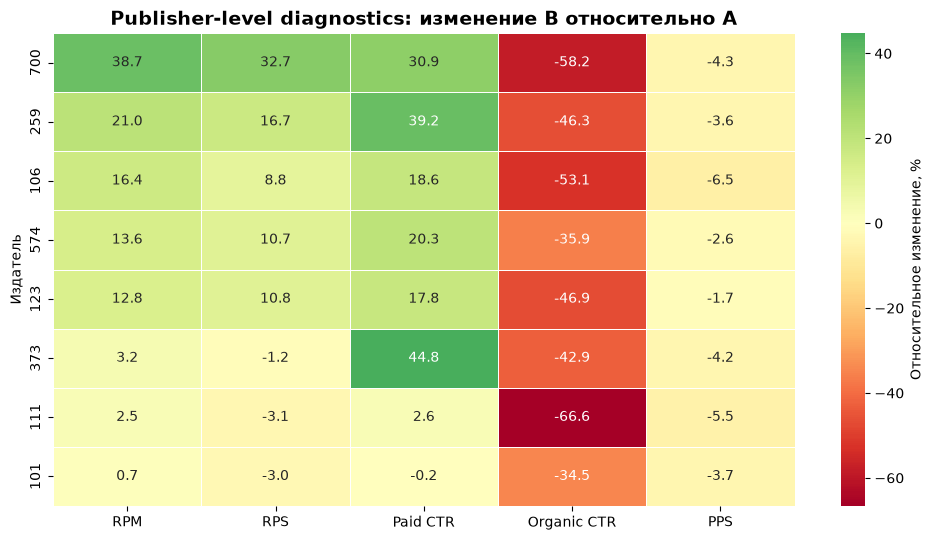

In [14]:
import seaborn as sns

heatmap_data = (publisher_results.pivot(index='publisher_id', columns='metric', values='relative_difference_pct')
    [['RPM', 'RPS', 'Paid CTR', 'Organic CTR', 'PPS']])

heatmap_data = heatmap_data.sort_values('RPM', ascending=False)

heatmap_data = heatmap_data.apply(lambda col: pd.to_numeric(col.astype(str).str.replace('%', '', regex=False).str.replace(',', '.', regex=False),errors='coerce'))
plt.figure(figsize=(10, 5.5))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn', center=0, linewidths=0.5, cbar_kws={'label': 'Относительное изменение, %'})
plt.title('Publisher-level diagnostics: изменение B относительно A', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('Издатель')
plt.tight_layout()
plt.savefig('svg/publisher_metric_heatmap.svg', format='svg',  bbox_inches='tight')
plt.show()

### Publisher-level diagnostics conclusion

Publisher-level разрез показывает, что эффект версии B неоднороден между издателями.

У большинства publisher наблюдается рост RPM и Paid CTR, но размер эффекта сильно различается. Самый заметный monetization uplift виден у publisher `700`: RPM вырос на 38.7%, RPS — на 32.7%, Paid CTR — на 30.9%.

При этом Organic CTR снижается у всех publisher без исключения. Падение особенно сильное у publisher `111` (-66.6%), `700` (-58.2%) и `106` (-53.1%). Это подтверждает общий риск: новая версия ленты перераспределяет внимание пользователей в сторону paid content и ухудшает взаимодействие с органическим контентом.

Pages per Session также снижается у всех publisher, но менее резко: примерно от -1.7% до -6.5%.

Так как внутри каждого publisher мало matched-блоков, этот разрез используется как descriptive diagnostics, а не как статистический тест. Он помогает понять, у каких publisher версия B выглядит наиболее выгодной по монетизации и где одновременно возникает наибольший guardrail-риск.

### AI_addition

In [ ]:
import json
from pathlib import Path


def dataframe_to_records(df):
    return json.loads(
        df.to_json(
            orient="records",
            force_ascii=False
        )
    )


diagnostic_results = {
    "platform": {
        "RPM": dataframe_to_records(rpm_platform_results),
        "RPS": dataframe_to_records(rps_platform_results),
        "Paid CTR": dataframe_to_records(paid_ctr_platform_results),
        "Organic CTR": dataframe_to_records(organic_ctr_platform_results),
        "Pages per Session": dataframe_to_records(pps_platform_results)
    },

    "publisher": dataframe_to_records(publisher_results),

    "methodology": {
        "platform_analysis": (
            "Paired bootstrap using matched blocks: "
            "date + publisher_id + platform."
        ),
        "publisher_analysis": (
            "Descriptive diagnostics only. "
            "Statistical significance is not evaluated at publisher level "
            "because the number of matched blocks per publisher is small."
        )
    }
}


output_path = Path("outputs/diagnostic_results.json")
output_path.parent.mkdir(exist_ok=True)

with output_path.open("w", encoding="utf-8") as f:
    json.dump(
        diagnostic_results,
        f,
        indent=2,
        ensure_ascii=False
    )

print(f"Saved to: {output_path}")